# Student Academic Performance: Exploratory Analysis and ML Readiness

> **SIMULATED DATA NOTICE.** Every number in this notebook is calculated from
> `student_academic_performance_synthetic_1000.csv`, a **synthetic** dataset created to test the research
> pipeline. It contains **no genuine questionnaire responses**. Timestamps are simulated and are not real
> submission times. None of the patterns below are findings about real students.

Project: *Machine Learning-Based Classification of Student Academic Performance Using Learning and Behavioural Factors*.

**Grading scheme used to define the target (applied only to `current_performance`, before any modelling):**

| Category | Mean score (%) | Kenyan degree-classification analogue |
|---|---|---|
| High | ≥ 60 | Upper Second Class and above |
| Medium | 50 – 59.9 | Lower Second Class |
| Low | < 50 | Pass band / marginal / failing |

Limitation: real universities differ in grading scales. With real data, record each institution's scale and
map it to these bands only where the mapping is defensible.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
if not (ROOT / "student_academic_performance_synthetic_1000.csv").exists():
    ROOT = ROOT.parent
CHARTS = ROOT / "charts"; RESULTS = ROOT / "results"
CHARTS.mkdir(exist_ok=True); RESULTS.mkdir(exist_ok=True)

# Palette (categorical slots 1-3, validated all-pairs) and chrome
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
ORDER = ["Low", "Medium", "High"]
CAT_COL = {"Low": BLUE, "Medium": ORANGE, "High": AQUA}
mpl.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 300, "figure.facecolor": SURF, "axes.facecolor": SURF,
    "savefig.facecolor": SURF, "font.family": "DejaVu Sans", "axes.edgecolor": MUTED,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "legend.frameon": False})
SIM = "SIMULATED DATA (synthetic pipeline-test dataset, not real student responses)"
def save(fig, name, top=1.02):
    fig.text(0.99, top, SIM, fontsize=6.5, color=MUTED, ha="right", va="bottom")
    fig.savefig(CHARTS / name, bbox_inches="tight", pad_inches=0.25); plt.show(); plt.close(fig)
S = {}   # summary of every number used in the written reports

## 1. Load and validate

In [2]:
df = pd.read_csv(ROOT / "student_academic_performance_synthetic_1000.csv", encoding="utf-8-sig")
S["n_rows"], S["n_cols"] = int(df.shape[0]), int(df.shape[1])
S["data_source_values"] = df["data_source"].unique().tolist()
S["duplicate_ids"] = int(df["student_id"].duplicated().sum())
S["duplicate_rows"] = int(df.drop(columns="student_id").duplicated().sum())
print(df.shape, S["data_source_values"], "duplicate ids:", S["duplicate_ids"])
df.dtypes.to_frame("dtype")

(1000, 17) ['SYNTHETIC'] duplicate ids: 0


,dtype
student_id,str
university,str
programme,str
year_of_study,int64
study_hours_weekly,float64
attendance_percentage,float64
assignment_completion_percentage,float64
sleep_hours,float64
internet_access,str
study_location,str


In [3]:
num_cols = ["study_hours_weekly","attendance_percentage","assignment_completion_percentage","sleep_hours",
            "number_of_courses","social_media_hours_daily","previous_performance","current_performance"]
cat_cols = ["internet_access","study_location","university","programme"]
rules = {  # plausible range per variable
 "study_hours_weekly": (0, 80), "attendance_percentage": (0, 100), "assignment_completion_percentage": (0, 100),
 "sleep_hours": (2, 14), "number_of_courses": (1, 12), "social_media_hours_daily": (0, 16),
 "previous_performance": (0, 100), "current_performance": (0, 100), "year_of_study": (1, 5)}
rows = []
for c, (lo, hi) in rules.items():
    s = df[c]
    rows.append({"variable": c, "allowed": f"{lo}-{hi}", "min": s.min(), "max": s.max(),
                 "missing": int(s.isna().sum()), "missing_%": round(100 * s.isna().mean(), 2),
                 "out_of_range": int(((s < lo) | (s > hi)).sum())})
validation = pd.DataFrame(rows)
validation.to_csv(RESULTS / "validation_ranges.csv", index=False)
S["validation"] = validation.to_dict("records")
S["total_missing_cells"] = int(df.isna().sum().sum())
S["rows_with_any_missing"] = int(df.isna().any(axis=1).sum())
S["categorical_levels"] = {c: sorted(df[c].dropna().unique().tolist()) for c in ["internet_access","study_location","performance_category","data_source"]}
S["ts_min"], S["ts_max"] = df["timestamp"].min(), df["timestamp"].max()
validation

,variable,allowed,min,max,missing,missing_%,out_of_range
0,study_hours_weekly,0-80,0.0,33.0,6,0.6,0
1,attendance_percentage,0-100,30.0,100.0,11,1.1,0
2,assignment_completion_percentage,0-100,15.0,100.0,0,0.0,0
3,sleep_hours,2-14,3.5,10.0,14,1.4,0
4,number_of_courses,1-12,3.0,10.0,0,0.0,0
5,social_media_hours_daily,0-16,0.0,8.2,13,1.3,0
6,previous_performance,0-100,25.6,85.2,16,1.6,0
7,current_performance,0-100,23.3,88.5,0,0.0,0
8,year_of_study,1-5,1.0,5.0,0,0.0,0


In [4]:
# Target consistency: the category must follow ONLY from current_performance and the documented thresholds
expected = np.where(df.current_performance >= 60, "High", np.where(df.current_performance >= 50, "Medium", "Low"))
S["target_mismatches"] = int((expected != df.performance_category).sum())
print("Rows where category disagrees with the documented thresholds:", S["target_mismatches"])

Rows where category disagrees with the documented thresholds: 0


## 2. Quality checks: outliers and descriptive statistics

In [5]:
def iqr_out(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return int(((s < q1 - 1.5*i) | (s > q3 + 1.5*i)).sum())
desc = df[num_cols].describe().T[["count","mean","std","min","25%","50%","75%","max"]].round(2)
desc["missing"] = df[num_cols].isna().sum()
desc["iqr_outliers"] = [iqr_out(df[c]) for c in num_cols]
desc.to_csv(RESULTS / "descriptive_statistics.csv")
S["descriptives"] = desc.reset_index().rename(columns={"index":"variable"}).to_dict("records")
desc

,count,mean,std,min,25%,50%,75%,max,missing,iqr_outliers
study_hours_weekly,994.0,12.16,7.18,0.0,7.0,12.0,17.0,33.0,6,1
attendance_percentage,989.0,75.66,13.15,30.0,67.0,76.0,85.0,100.0,11,4
assignment_completion_percentage,1000.0,77.58,14.74,15.0,67.0,78.0,89.0,100.0,0,5
sleep_hours,986.0,6.60,1.13,3.5,5.8,6.6,7.3,10.0,14,11
number_of_courses,1000.0,6.27,1.35,3.0,5.0,6.0,7.0,10.0,0,0
social_media_hours_daily,987.0,3.59,1.61,0.0,2.5,3.6,4.7,8.2,13,2
previous_performance,984.0,56.42,10.27,25.6,49.5,56.2,63.5,85.2,16,3
current_performance,1000.0,56.37,10.09,23.3,49.5,56.7,62.8,88.5,0,9


## 3. Distributions

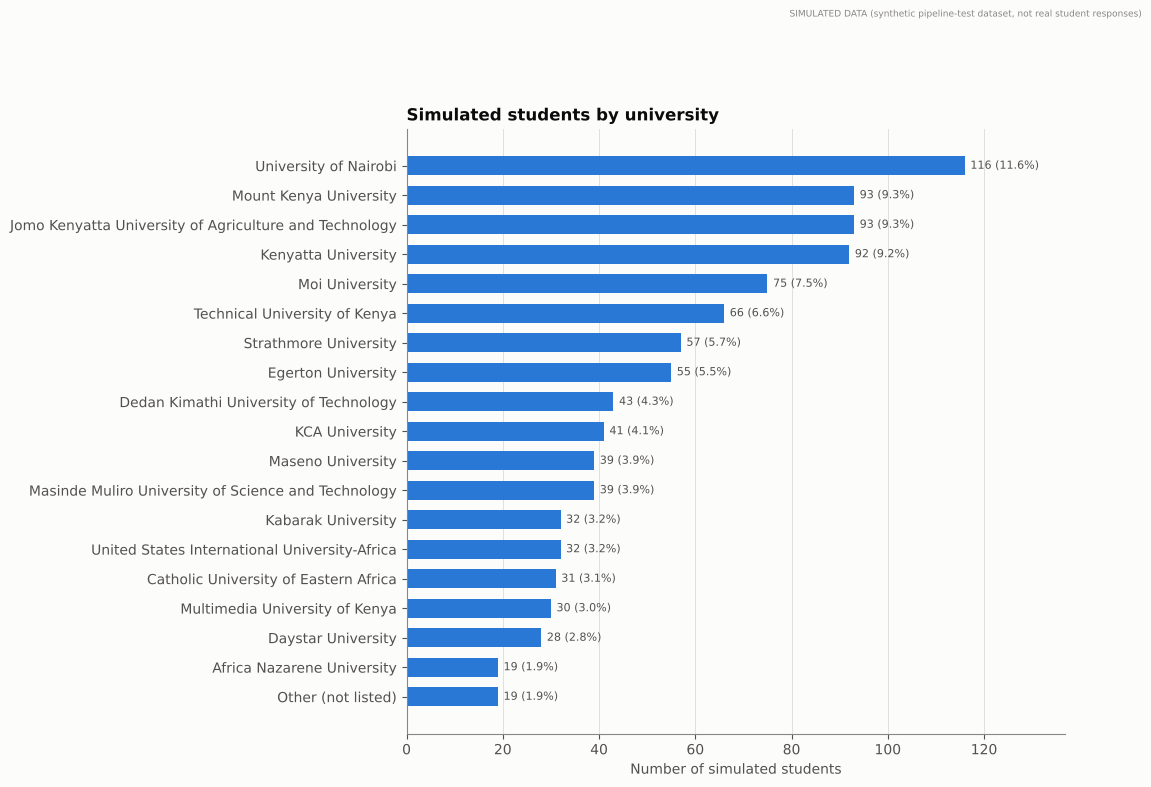

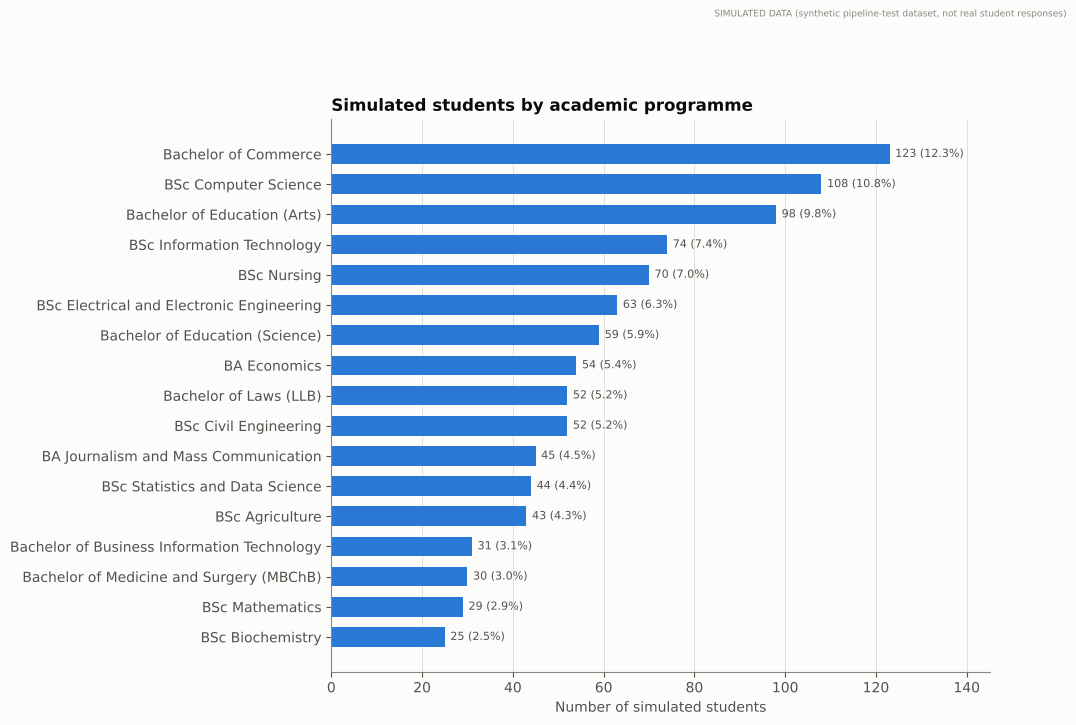

In [6]:
def freq(col):
    t = df[col].value_counts().rename_axis(col).reset_index(name="count")
    t["percent"] = (100 * t["count"] / len(df)).round(1); return t
for c in ["university","programme","year_of_study","performance_category","internet_access","study_location"]:
    t = freq(c); t.to_csv(RESULTS / f"freq_{c}.csv", index=False); S[f"freq_{c}"] = t.to_dict("records")

def hbar(col, title, fname, color=BLUE, ylabel=""):
    t = freq(col).sort_values("count")
    fig, ax = plt.subplots(figsize=(8.5, max(3, 0.34 * len(t) + 1.4)))
    ax.barh(t[col].astype(str), t["count"], color=color, height=0.65)
    for y, (n, p) in enumerate(zip(t["count"], t["percent"])):
        ax.text(n + t["count"].max() * 0.01, y, f"{n} ({p}%)", va="center", fontsize=8, color=INK2)
    ax.set_xlabel("Number of simulated students"); ax.set_ylabel(ylabel); ax.set_title(title)
    ax.set_xlim(0, t["count"].max() * 1.18); ax.grid(axis="y", visible=False)
    save(fig, fname)

hbar("university", "Simulated students by university", "01_students_by_university.png")
hbar("programme", "Simulated students by academic programme", "02_students_by_programme.png")

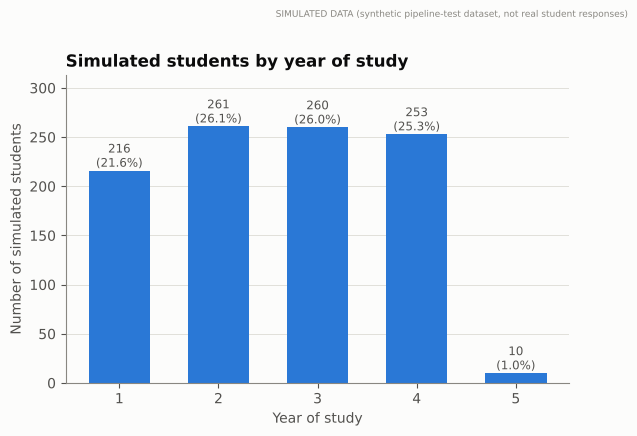

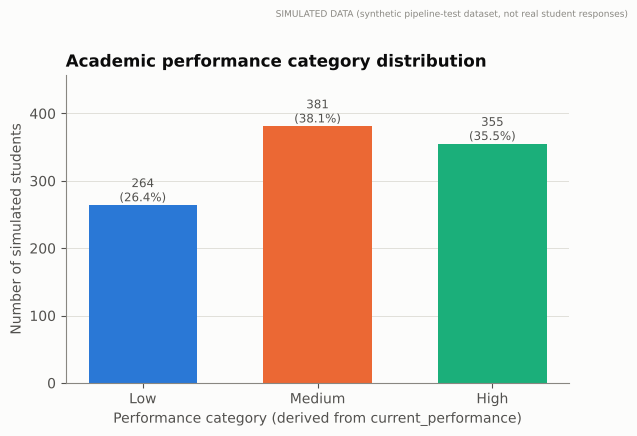

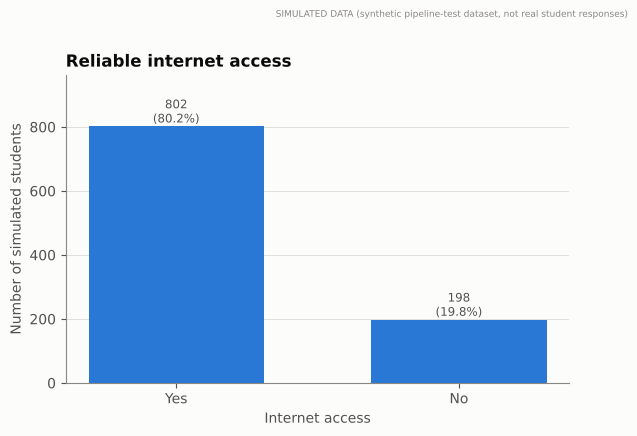

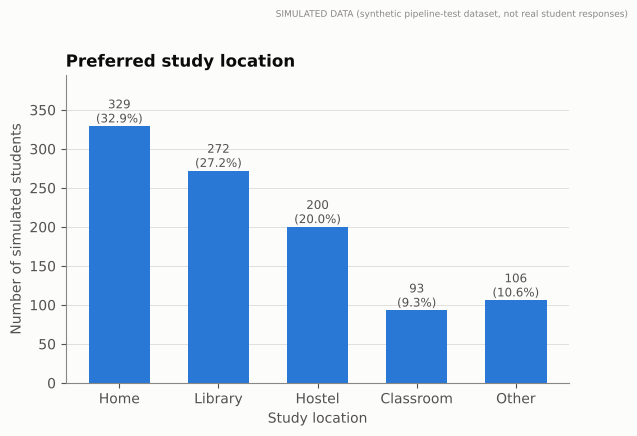

In [7]:
def vbar(col, title, fname, xlabel, order=None, colors=None):
    t = freq(col)
    t = t.set_index(col).loc[order].reset_index() if order else t.sort_values(col)
    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.bar(t[col].astype(str), t["count"], color=colors or BLUE, width=0.62)
    for x, (n, p) in enumerate(zip(t["count"], t["percent"])):
        ax.text(x, n + t["count"].max() * 0.015, f"{n}\n({p}%)", ha="center", fontsize=8.5, color=INK2)
    ax.set_xlabel(xlabel); ax.set_ylabel("Number of simulated students"); ax.set_title(title)
    ax.set_ylim(0, t["count"].max() * 1.2); ax.grid(axis="x", visible=False)
    save(fig, fname)

vbar("year_of_study", "Simulated students by year of study", "03_students_by_year.png", "Year of study")
vbar("performance_category", "Academic performance category distribution", "04_performance_category_distribution.png",
     "Performance category (derived from current_performance)", ORDER, [CAT_COL[c] for c in ORDER])
vbar("internet_access", "Reliable internet access", "10_internet_access_distribution.png", "Internet access", ["Yes","No"])
vbar("study_location", "Preferred study location", "11_study_location_distribution.png", "Study location",
     ["Home","Library","Hostel","Classroom","Other"])

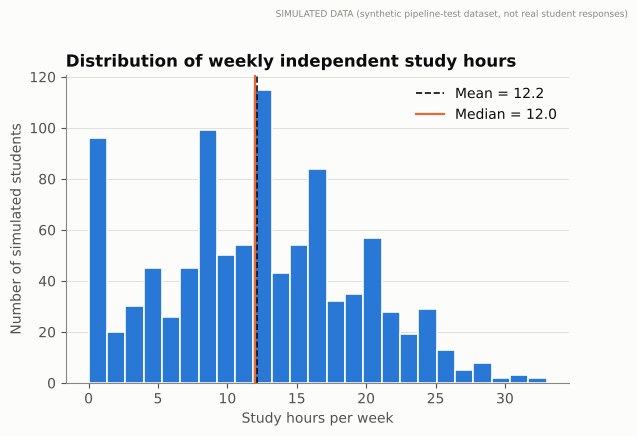

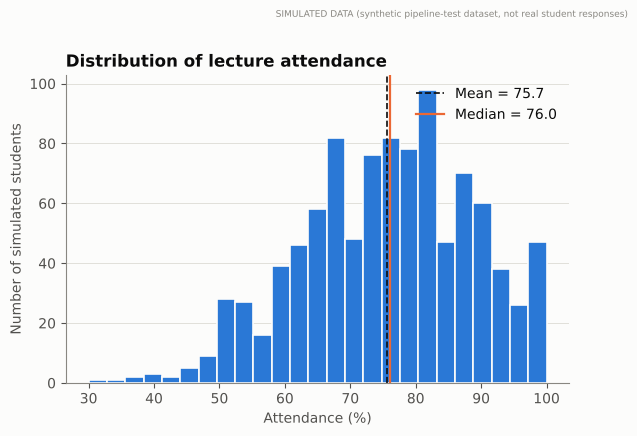

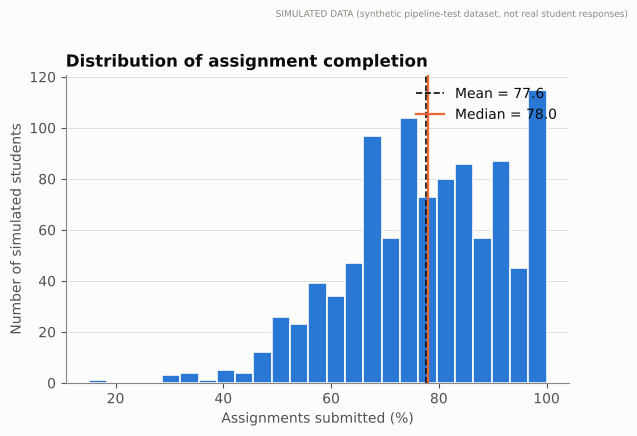

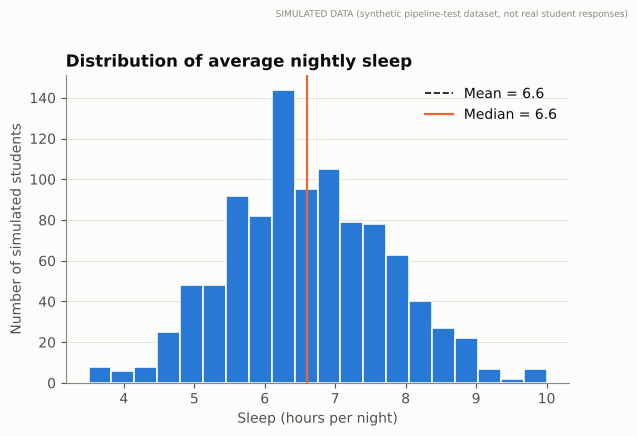

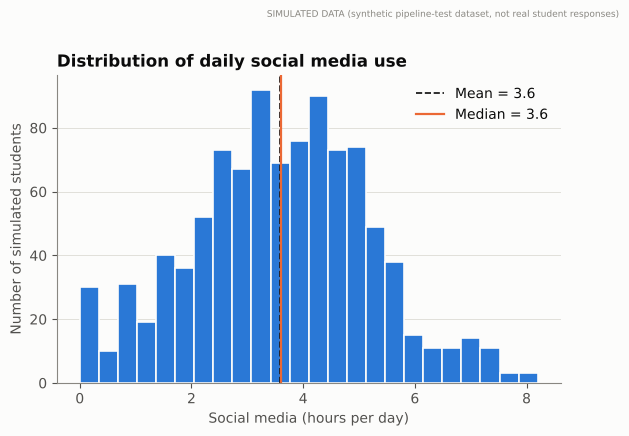

In [8]:
def hist(col, title, fname, xlabel, bins=25):
    s = df[col].dropna()
    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.hist(s, bins=bins, color=BLUE, edgecolor=SURF, linewidth=1.2)
    ax.axvline(s.mean(), color=INK, lw=1.2, ls="--", label=f"Mean = {s.mean():.1f}")
    ax.axvline(s.median(), color=ORANGE, lw=1.6, label=f"Median = {s.median():.1f}")
    ax.set_xlabel(xlabel); ax.set_ylabel("Number of simulated students"); ax.set_title(title)
    ax.legend(loc="upper right"); ax.grid(axis="x", visible=False)
    save(fig, fname)

hist("study_hours_weekly", "Distribution of weekly independent study hours", "05_study_hours_distribution.png", "Study hours per week")
hist("attendance_percentage", "Distribution of lecture attendance", "06_attendance_distribution.png", "Attendance (%)")
hist("assignment_completion_percentage", "Distribution of assignment completion", "07_assignment_completion_distribution.png", "Assignments submitted (%)")
hist("sleep_hours", "Distribution of average nightly sleep", "08_sleep_distribution.png", "Sleep (hours per night)", 20)
hist("social_media_hours_daily", "Distribution of daily social media use", "09_social_media_distribution.png", "Social media (hours per day)", 24)

## 4. Previous vs current performance, and predictors by category

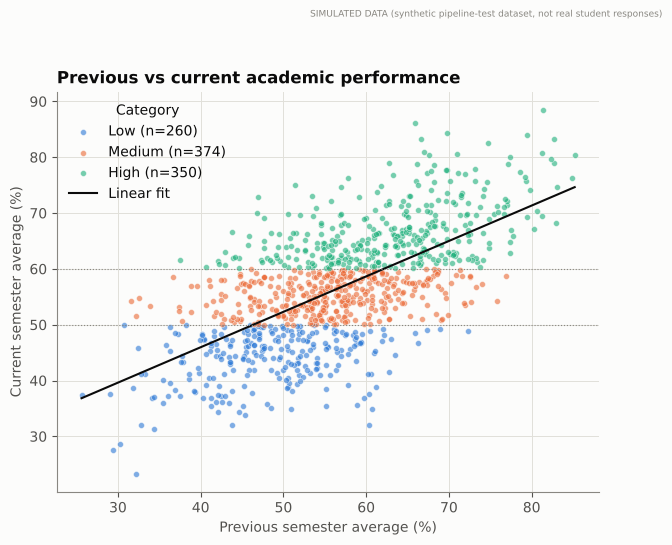

0.643 0.619


In [9]:
d = df.dropna(subset=["previous_performance"])
fig, ax = plt.subplots(figsize=(7, 5.2))
for c in ORDER:
    s = d[d.performance_category == c]
    ax.scatter(s.previous_performance, s.current_performance, s=18, alpha=0.6, color=CAT_COL[c],
               edgecolor=SURF, linewidth=0.5, label=f"{c} (n={len(s)})")
m, b = np.polyfit(d.previous_performance, d.current_performance, 1)
xs = np.linspace(d.previous_performance.min(), d.previous_performance.max(), 50)
ax.plot(xs, m * xs + b, color=INK, lw=1.5, label="Linear fit")
for y in (50, 60): ax.axhline(y, color=MUTED, lw=0.8, ls=":")
ax.set_xlabel("Previous semester average (%)"); ax.set_ylabel("Current semester average (%)")
ax.set_title("Previous vs current academic performance"); ax.legend(title="Category", loc="upper left")
save(fig, "12_previous_vs_current_performance.png")
S["prev_cur_pearson"] = round(float(d[["previous_performance","current_performance"]].corr().iloc[0, 1]), 3)
S["prev_cur_spearman"] = round(float(d[["previous_performance","current_performance"]].corr(method="spearman").iloc[0, 1]), 3)
S["prev_cur_slope"], S["prev_cur_intercept"] = round(float(m), 3), round(float(b), 2)
S["prev_cur_n"] = int(len(d))
print(S["prev_cur_pearson"], S["prev_cur_spearman"])

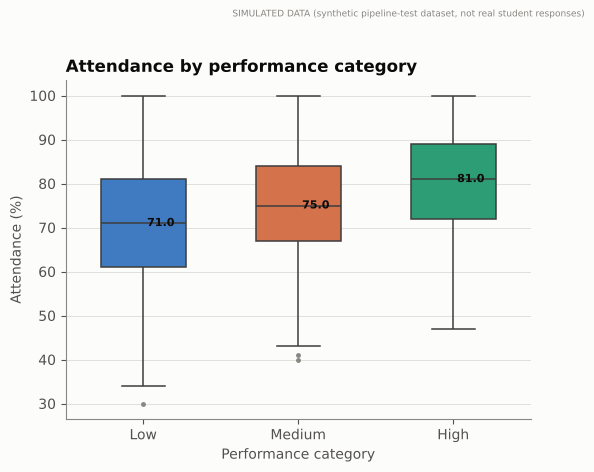

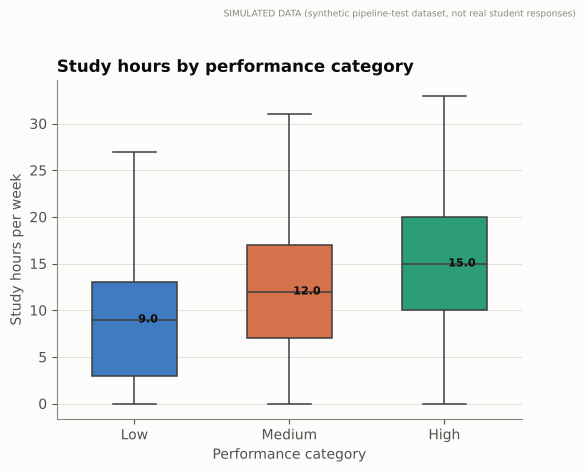

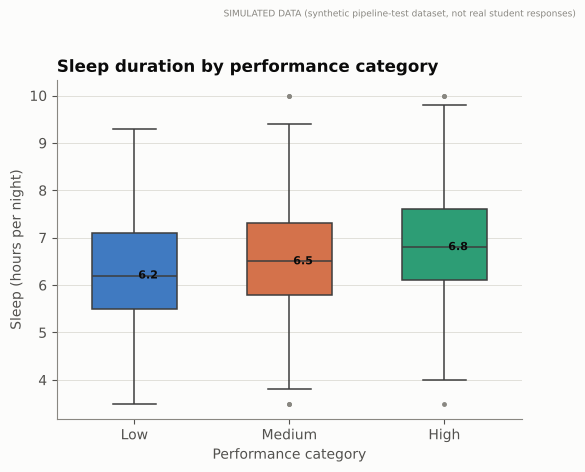

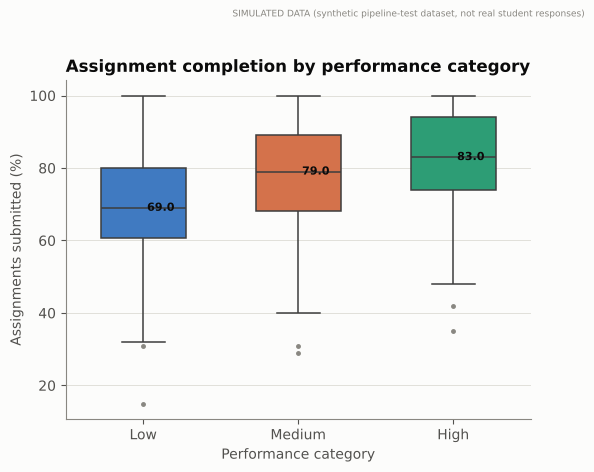

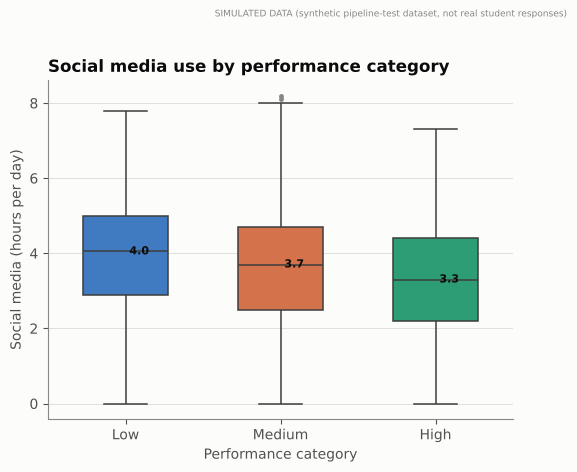

,variable,median_Low,median_Medium,median_High,mean_Low,mean_Medium,mean_High,kruskal_H,p_value
0,attendance_percentage,71.00,75.0,81.0,70.61,75.20,79.88,69.86,6.764033e-16
1,study_hours_weekly,9.00,12.0,15.0,8.98,11.58,15.15,109.42,1.736482e-24
2,sleep_hours,6.20,6.5,6.8,6.29,6.61,6.81,33.43,5.505464e-08
3,assignment_completion_percentage,69.00,79.0,83.0,69.75,77.98,82.99,119.69,1.021693e-26
4,social_media_hours_daily,4.05,3.7,3.3,3.95,3.63,3.28,25.37,3.104425e-06


In [10]:
box_specs = [("attendance_percentage","13_attendance_by_category.png","Attendance (%)","Attendance by performance category"),
 ("study_hours_weekly","14_study_hours_by_category.png","Study hours per week","Study hours by performance category"),
 ("sleep_hours","15_sleep_by_category.png","Sleep (hours per night)","Sleep duration by performance category"),
 ("assignment_completion_percentage","16_assignment_completion_by_category.png","Assignments submitted (%)","Assignment completion by performance category"),
 ("social_media_hours_daily","17_social_media_by_category.png","Social media (hours per day)","Social media use by performance category")]
tests = []
for col, fname, ylab, title in box_specs:
    fig, ax = plt.subplots(figsize=(6, 4.4))
    sns.boxplot(data=df, x="performance_category", y=col, order=ORDER, palette=CAT_COL, width=0.55, linewidth=1.1,
                fliersize=2.5, flierprops={"markerfacecolor": MUTED, "markeredgecolor": MUTED}, ax=ax)
    for i, c in enumerate(ORDER):
        med = df.loc[df.performance_category == c, col].median()
        ax.text(i, med, f" {med:.1f}", va="center", ha="left", fontsize=8, color=INK, fontweight="bold")
    ax.set_xlabel("Performance category"); ax.set_ylabel(ylab); ax.set_title(title); ax.grid(axis="x", visible=False)
    save(fig, fname)
    groups = [df.loc[df.performance_category == c, col].dropna() for c in ORDER]
    H, p = stats.kruskal(*groups)
    tests.append({"variable": col, **{f"median_{c}": round(float(g.median()), 2) for c, g in zip(ORDER, groups)},
                  **{f"mean_{c}": round(float(g.mean()), 2) for c, g in zip(ORDER, groups)},
                  "kruskal_H": round(float(H), 2), "p_value": float(p)})
tests = pd.DataFrame(tests); tests.to_csv(RESULTS / "predictors_by_category.csv", index=False)
S["predictor_tests"] = tests.to_dict("records")
tests

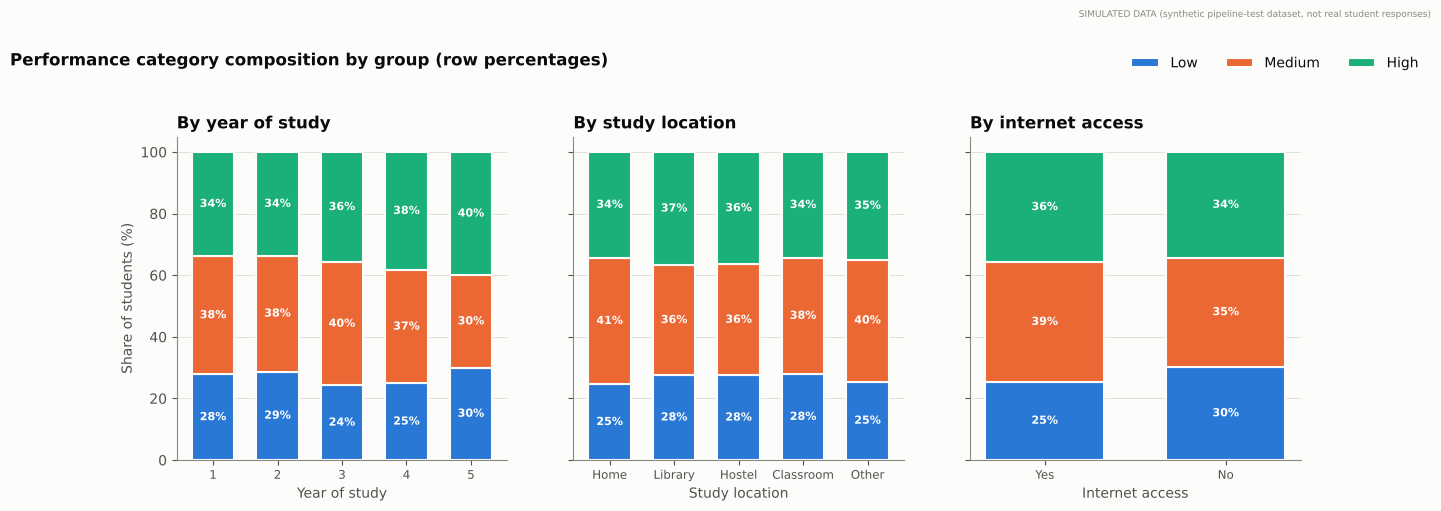

performance_category,Low,Medium,High
study_location,,,
Classroom,26,35,32
Home,81,135,113
Hostel,55,72,73
Library,75,97,100
Other,27,42,37


In [11]:
# Stacked (100%) bars: category composition by year, study location and internet access
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.2), sharey=True)
for ax, (col, ttl, order) in zip(axes, [("year_of_study","By year of study",[1,2,3,4,5]),
        ("study_location","By study location",["Home","Library","Hostel","Classroom","Other"]),
        ("internet_access","By internet access",["Yes","No"])]):
    ct = pd.crosstab(df[col], df.performance_category, normalize="index").loc[order, ORDER] * 100
    bottom = np.zeros(len(ct))
    for c in ORDER:
        ax.bar(ct.index.astype(str), ct[c], bottom=bottom, color=CAT_COL[c], edgecolor=SURF, linewidth=1.5, width=0.66, label=c)
        for x, (v, b0) in enumerate(zip(ct[c], bottom)):
            if v >= 7: ax.text(x, b0 + v / 2, f"{v:.0f}%", ha="center", va="center", fontsize=8, color="#ffffff", fontweight="bold")
        bottom += ct[c].values
    ax.set_title(ttl); ax.set_xlabel(col.replace("_", " ").capitalize()); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Share of students (%)")
for ax in axes: ax.tick_params(axis="x", labelsize=8.5)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper right", bbox_to_anchor=(0.99, 1.1), ncol=3, title=None)
fig.suptitle("Performance category composition by group (row percentages)", x=0.01, ha="left", fontsize=12, fontweight="bold", y=1.08)
save(fig, "19_category_composition_stacked.png", top=1.16)
for col in ["year_of_study","study_location","internet_access"]:
    ct = pd.crosstab(df[col], df.performance_category).loc[:, ORDER]
    ct.to_csv(RESULTS / f"crosstab_{col}_by_category.csv"); S[f"crosstab_{col}"] = ct.reset_index().to_dict("records")
    S[f"chi2_{col}"] = {"chi2": round(float(stats.chi2_contingency(ct)[0]), 2), "p": float(stats.chi2_contingency(ct)[1]), "dof": int(stats.chi2_contingency(ct)[2])}
pd.crosstab(df.study_location, df.performance_category).loc[:, ORDER]

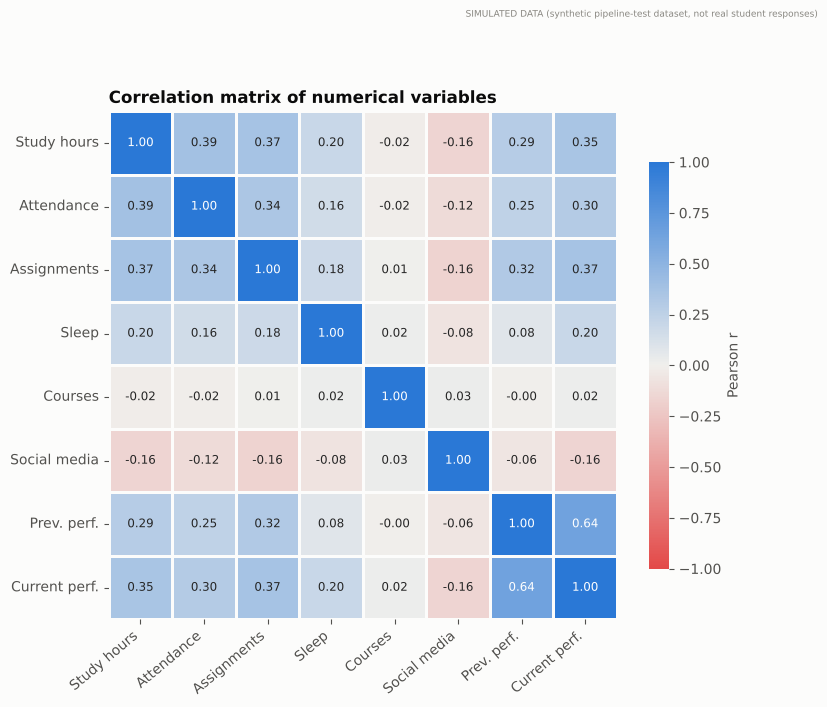

,study_hours_weekly,attendance_percentage,assignment_completion_percentage,sleep_hours,number_of_courses,social_media_hours_daily,previous_performance,current_performance
study_hours_weekly,1.00,0.39,0.37,0.20,-0.02,-0.16,0.29,0.35
attendance_percentage,0.39,1.00,0.34,0.16,-0.02,-0.12,0.25,0.30
assignment_completion_percentage,0.37,0.34,1.00,0.18,0.01,-0.16,0.32,0.37
sleep_hours,0.20,0.16,0.18,1.00,0.02,-0.08,0.08,0.20
number_of_courses,-0.02,-0.02,0.01,0.02,1.00,0.03,-0.00,0.02
social_media_hours_daily,-0.16,-0.12,-0.16,-0.08,0.03,1.00,-0.06,-0.16
previous_performance,0.29,0.25,0.32,0.08,-0.00,-0.06,1.00,0.64
current_performance,0.35,0.30,0.37,0.20,0.02,-0.16,0.64,1.00


In [12]:
cm = df[num_cols].corr()
cm.round(3).to_csv(RESULTS / "correlation_matrix.csv")
S["corr_with_current"] = cm["current_performance"].drop("current_performance").round(3).to_dict()
S["corr_pairs_top"] = (cm.where(np.triu(np.ones(cm.shape), 1).astype(bool)).stack().rename("r").reset_index()
        .assign(abs_r=lambda t: t.r.abs()).sort_values("abs_r", ascending=False).head(8).round(3).to_dict("records"))
cmap = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
labels = ["Study hours","Attendance","Assignments","Sleep","Courses","Social media","Prev. perf.","Current perf."]
fig, ax = plt.subplots(figsize=(8.2, 6.6))
sns.heatmap(cm, annot=True, fmt=".2f", cmap=cmap, vmin=-1, vmax=1, center=0, square=True, linewidths=2, linecolor=SURF,
            xticklabels=labels, yticklabels=labels, cbar_kws={"label": "Pearson r", "shrink": 0.8}, annot_kws={"size": 8.5}, ax=ax)
ax.set_title("Correlation matrix of numerical variables"); ax.grid(False); plt.xticks(rotation=40, ha="right")
save(fig, "18_correlation_heatmap.png")
cm.round(2)

## 5. Machine-learning readiness

Intended predictors: study hours, attendance, assignment completion, sleep, internet access, study location,
number of courses, social media hours, previous performance. **Excluded from features:** `student_id`,
`university`, `programme`, `year_of_study`, `timestamp`, `data_source` (identifiers or administrative fields with no
scientific justification as predictors) and **`current_performance`** (the target is derived from it, so it is
leakage by construction).

In [13]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix, classification_report

NUM = ["study_hours_weekly","attendance_percentage","assignment_completion_percentage","sleep_hours",
       "number_of_courses","social_media_hours_daily","previous_performance"]
CAT = ["internet_access","study_location"]
SEED = 42
X, y = df[NUM + CAT], df["performance_category"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
S["split"] = {"train": int(len(Xtr)), "test": int(len(Xte)),
              "train_dist": ytr.value_counts().reindex(ORDER).to_dict(), "test_dist": yte.value_counts().reindex(ORDER).to_dict()}
cls = y.value_counts().reindex(ORDER)
S["imbalance"] = {"counts": cls.to_dict(), "ratio_max_to_min": round(float(cls.max() / cls.min()), 2),
                  "majority_class": cls.idxmax(), "majority_share": round(float(cls.max() / cls.sum()), 3)}
print(S["split"], S["imbalance"])

{'train': 800, 'test': 200, 'train_dist': {'Low': 211, 'Medium': 305, 'High': 284}, 'test_dist': {'Low': 53, 'Medium': 76, 'High': 71}} {'counts': {'Low': 264, 'Medium': 381, 'High': 355}, 'ratio_max_to_min': 1.44, 'majority_class': 'Medium', 'majority_share': 0.381}


In [14]:
def make_pipe(model, num=NUM, cat=CAT):
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat)])
    return Pipeline([("pre", pre), ("clf", model)])

models = {
 "Majority baseline": DummyClassifier(strategy="most_frequent"),
 "Logistic Regression": LogisticRegression(C=1.0, max_iter=2000, random_state=SEED),
 "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1)}
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
res, fitted, preds = [], {}, {}
for name, mdl in models.items():
    p = make_pipe(mdl)
    cv = cross_val_score(p, Xtr, ytr, cv=skf, scoring="f1_macro")
    p.fit(Xtr, ytr); yp = p.predict(Xte); fitted[name], preds[name] = p, yp
    res.append({"model": name, "cv_macro_f1_mean": round(cv.mean(), 4), "cv_macro_f1_sd": round(cv.std(), 4),
                "test_accuracy": round(accuracy_score(yte, yp), 4),
                "test_macro_precision": round(precision_score(yte, yp, average="macro", zero_division=0), 4),
                "test_macro_recall": round(recall_score(yte, yp, average="macro", zero_division=0), 4),
                "test_macro_f1": round(f1_score(yte, yp, average="macro", zero_division=0), 4)})
results = pd.DataFrame(res); results.to_csv(RESULTS / "pipeline_test_model_metrics.csv", index=False)
S["model_results"] = results.to_dict("records")
S["confusion"] = {n: confusion_matrix(yte, preds[n], labels=ORDER).tolist() for n in models}
results

,model,cv_macro_f1_mean,cv_macro_f1_sd,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1
0,Majority baseline,0.1840,0.0000,0.380,0.1267,0.3333,0.1836
1,Logistic Regression,0.5702,0.0213,0.560,0.5575,0.5587,0.5558
2,Random Forest,0.5795,0.0171,0.555,0.5513,0.5477,0.5487


In [15]:
# Redundancy of previous performance: refit LR and RF without it, and with it alone
def evaluate(num_feats, cat_feats, label):
    out = {"feature_set": label}
    for name in ["Logistic Regression", "Random Forest"]:
        mdl = models[name]
        p = make_pipe(mdl.__class__(**mdl.get_params()), num_feats, cat_feats)
        p.fit(Xtr[num_feats + cat_feats], ytr); yp = p.predict(Xte[num_feats + cat_feats])
        out[f"{name} test macro-F1"] = round(f1_score(yte, yp, average="macro"), 4)
        out[f"{name} test accuracy"] = round(accuracy_score(yte, yp), 4)
    return out
abl = pd.DataFrame([
    evaluate(NUM, CAT, "All nine predictors"),
    evaluate([c for c in NUM if c != "previous_performance"], CAT, "Without previous_performance"),
    evaluate(["previous_performance"], [], "previous_performance only")])
abl.to_csv(RESULTS / "previous_performance_ablation.csv", index=False)
S["ablation"] = abl.to_dict("records"); abl

,feature_set,Logistic Regression test macro-F1,Logistic Regression test accuracy,Random Forest test macro-F1,Random Forest test accuracy
0,All nine predictors,0.5558,0.56,0.5487,0.555
1,Without previous_performance,0.4544,0.46,0.4618,0.460
2,previous_performance only,0.5701,0.57,0.5609,0.560


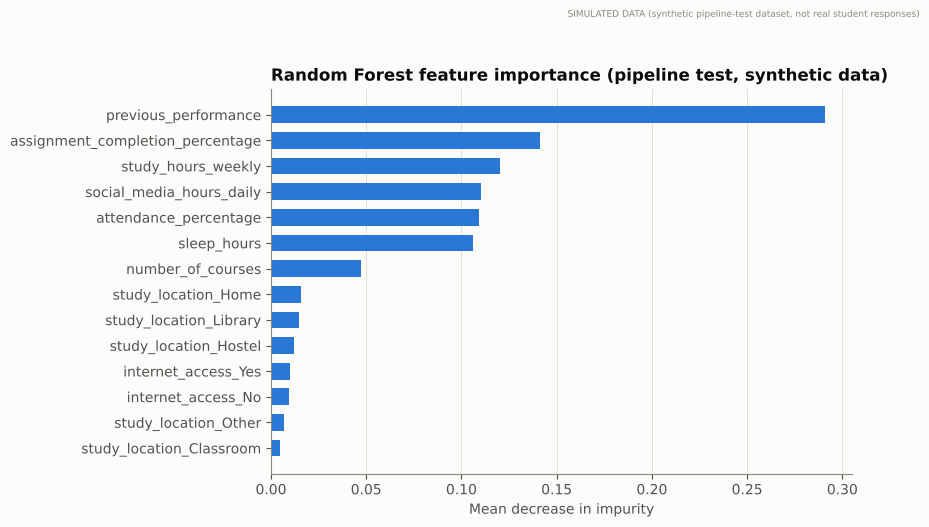

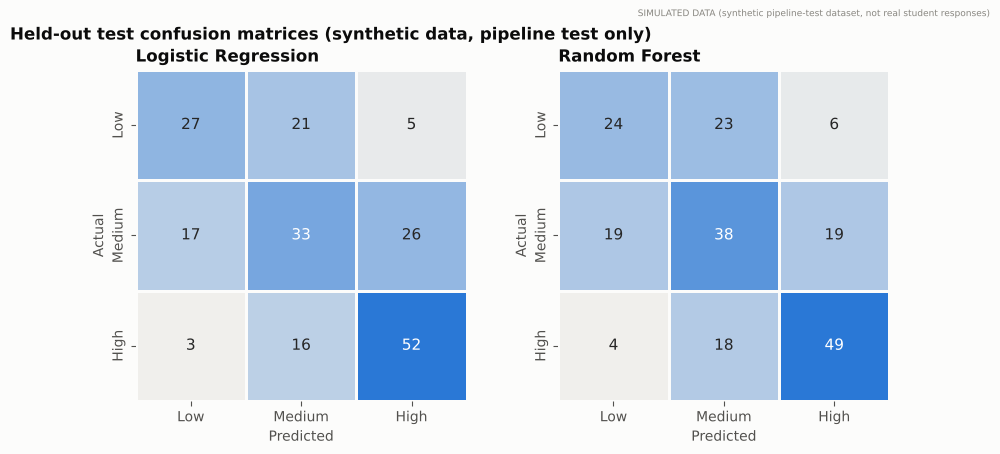

num__previous_performance                0.2907
num__assignment_completion_percentage    0.1412
num__study_hours_weekly                  0.1203
num__social_media_hours_daily            0.1105
num__attendance_percentage               0.1094
num__sleep_hours                         0.1062
num__number_of_courses                   0.0475
cat__study_location_Home                 0.0158
cat__study_location_Library              0.0150
cat__study_location_Hostel               0.0119
cat__internet_access_Yes                 0.0102
cat__internet_access_No                  0.0095
cat__study_location_Other                0.0068
cat__study_location_Classroom            0.0050
dtype: float64

In [16]:
# Feature importance / coefficients (descriptive of prediction, not causal)
rf = fitted["Random Forest"]; lr = fitted["Logistic Regression"]
names = rf.named_steps["pre"].get_feature_names_out()
imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=names).sort_values()
imp.to_csv(RESULTS / "rf_feature_importance.csv", header=["importance"])
S["rf_importance"] = imp.sort_values(ascending=False).round(4).to_dict()
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh([n.split("__")[1] for n in imp.index], imp.values, color=BLUE, height=0.65)
ax.set_xlabel("Mean decrease in impurity"); ax.set_title("Random Forest feature importance (pipeline test, synthetic data)")
ax.grid(axis="y", visible=False); save(fig, "20_rf_feature_importance.png")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
for ax, name in zip(axes, ["Logistic Regression", "Random Forest"]):
    cmx = confusion_matrix(yte, preds[name], labels=ORDER)
    sns.heatmap(cmx, annot=True, fmt="d", cmap=LinearSegmentedColormap.from_list("s", ["#f0efec", "#2a78d6"]),
                xticklabels=ORDER, yticklabels=ORDER, cbar=False, linewidths=2, linecolor=SURF, square=True, ax=ax, annot_kws={"size": 11})
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.grid(False)
fig.suptitle("Held-out test confusion matrices (synthetic data, pipeline test only)", x=0.01, ha="left", fontsize=12, fontweight="bold")
save(fig, "21_confusion_matrices.png", top=1.0)
imp.sort_values(ascending=False).round(4)

In [17]:
with open(RESULTS / "summary.json", "w") as f:
    json.dump(S, f, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Saved summary.json; charts:", len(list(CHARTS.glob('*.png'))))

Saved summary.json; charts: 21


## 6. Reading these results

* All figures describe a **synthetic** dataset whose structure was chosen by the simulation design. Agreement between
  predictors and category here reflects that design, not any real-world relationship.
* Use this notebook as a **template**: when genuine responses exist, point `df` at the real export, re-validate
  ranges and grading-scale mapping, and re-run. Do not carry any number from this run into a paper about real students.
* Model metrics above come from a single 80:20 split and are shown only to prove the pipeline runs end to end.